In [1]:
# Kiểm định baseline local; chỉ đọc artifacts, không fit lại.
from pathlib import Path
import json
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from quantstream import terminal

ROOT = Path.cwd()
if not (ROOT/'workspace').exists():
    ROOT = ROOT.parent
WORK = Path(os.environ.get('QUANTSTREAM_REVIEW_ROOT', ROOT/'workspace')).resolve()
meta = terminal.read_json(WORK/'artifacts/champion.json')
run = WORK/meta['run']
metrics = pd.read_json(run/'validation_metrics.json')
bars = pd.read_parquet(run/'training_bars.parquet')
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'bold', 'font.size': 10})
COLORS = ['#0f766e','#2563eb','#64748b','#b45309']
display(bars.groupby('symbol').agg(candles=('timestamp','size'), first=('timestamp','min'), last=('timestamp','max')))
print('Model:', meta['model'], '· fit:', meta['created_at'])
print('Nguồn: Binance Spot; validation đã dùng so model, chưa phải final test độc lập.')

Model: ridge · fit: 2026-11-20T17:53:31.791242+00:00
Nguồn: Binance Spot; validation đã dùng so model, chưa phải final test độc lập.


,candles,first,last
symbol,,,
BTCUSDT,33910,2023-01-01 00:00:00+00:00,2026-11-13 23:00:00+00:00
ETHUSDT,33910,2023-01-01 00:00:00+00:00,2026-11-13 23:00:00+00:00


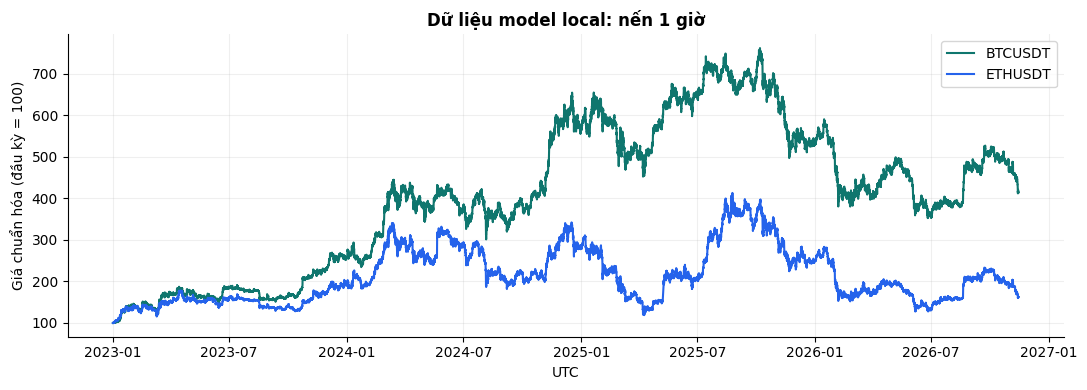

In [2]:
# Chuỗi giá train thực tế; mỗi tài sản chuẩn hóa về 100.
fig, ax = plt.subplots()
for (symbol, group), color in zip(bars.groupby('symbol'), COLORS):
    group = group.sort_values('timestamp')
    ax.plot(group.timestamp, group.close/group.close.iloc[0]*100, label=symbol, color=color)
ax.set(title='Dữ liệu model local: nến 1 giờ', xlabel='UTC', ylabel='Giá chuẩn hóa (đầu kỳ = 100)')
ax.legend(); ax.grid(alpha=.2); plt.tight_layout(); plt.show()

,model,rows,mae,mse,mse_ratio_to_zero,directional_accuracy
0,ridge,1878,0.006204,0.000095,0.994550,0.466986
1,xgboost_d3,1878,0.006181,0.000095,0.998255,0.512780
2,zero_return,1878,0.006170,0.000095,1.000000,0.532481
3,naive_ret4,1878,0.009430,0.000197,2.071623,0.495208


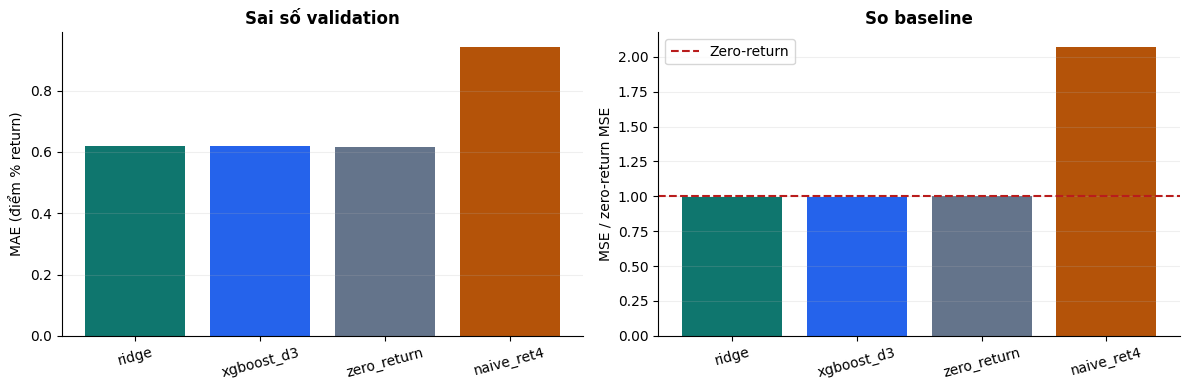

In [3]:
# MSE dưới 1 mới vượt zero-return; giữ cả các cấu hình kém baseline.
display(metrics.round(6))
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].bar(metrics.model, metrics.mae*100, color=COLORS)
axes[0].set(title='Sai số validation', ylabel='MAE (điểm % return)')
axes[1].bar(metrics.model, metrics.mse_ratio_to_zero, color=COLORS)
axes[1].axhline(1,color='#b91c1c',linestyle='--',label='Zero-return')
axes[1].set(title='So baseline',ylabel='MSE / zero-return MSE'); axes[1].legend()
for ax in axes:
    ax.tick_params(axis='x',rotation=15); ax.grid(axis='y',alpha=.2)
plt.tight_layout(); plt.show()

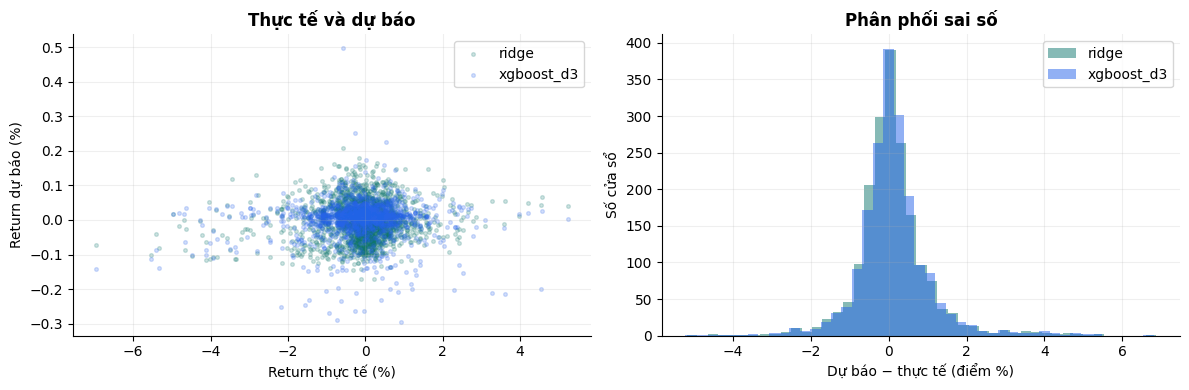

rows                     start                       end
model      fold                                                          
ridge      0      622 2026-10-05 07:00:00+00:00 2026-10-18 10:00:00+00:00
           1      622 2026-10-18 11:00:00+00:00 2026-10-31 14:00:00+00:00
           2      634 2026-10-31 15:00:00+00:00 2026-11-14 00:00:00+00:00
xgboost_d3 0      622 2026-10-05 07:00:00+00:00 2026-10-18 10:00:00+00:00
           1      622 2026-10-18 11:00:00+00:00 2026-10-31 14:00:00+00:00
           2      634 2026-10-31 15:00:00+00:00 2026-11-14 00:00:00+00:00

In [4]:
# Dự báo ngoài train của từng fold; các nhãn chồng lấn đã purge ở biên.
oof = pd.read_parquet(run/'validation_predictions.parquet')
fig, axes = plt.subplots(1,2,figsize=(12,4))
for (name, group), color in zip(oof.groupby('model'), COLORS):
    axes[0].scatter(group.target_return*100, group.prediction*100, s=7, alpha=.2, color=color, label=name)
    axes[1].hist((group.prediction-group.target_return)*100,bins=45,alpha=.5,color=color,label=name)
axes[0].set(title='Thực tế và dự báo',xlabel='Return thực tế (%)',ylabel='Return dự báo (%)')
axes[1].set(title='Phân phối sai số',xlabel='Dự báo − thực tế (điểm %)',ylabel='Số cửa sổ')
for ax in axes:
    ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()
display(oof.groupby(['model','fold']).agg(rows=('prediction','size'),start=('decision_time','min'),end=('label_end_time','max')))

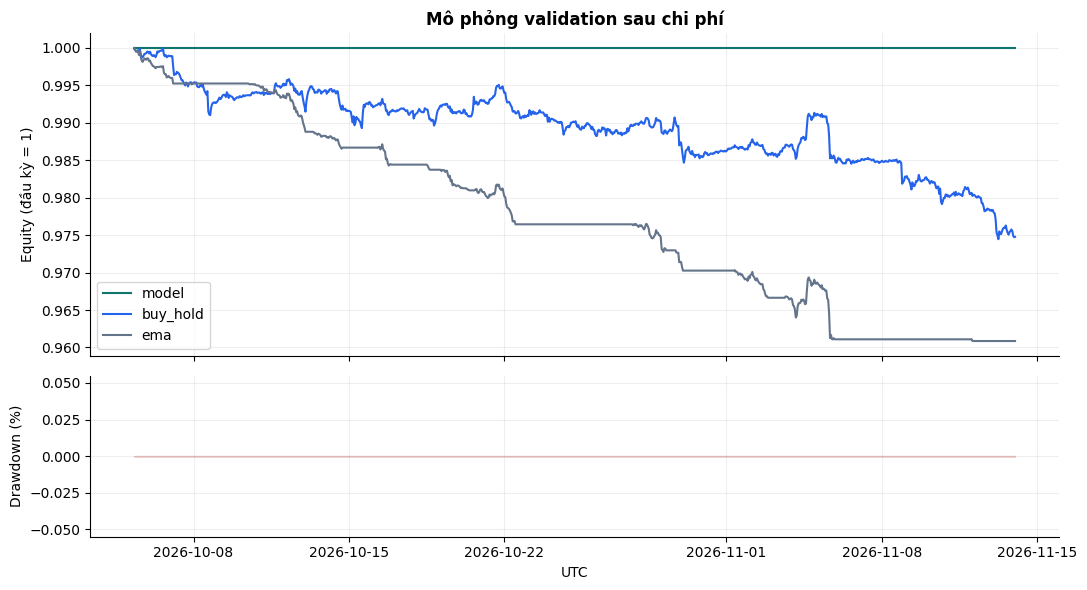

,strategy,total_return,sharpe_hourly_estimate,max_drawdown,trades,win_rate,turnover
0,strategy,0.000000,0.000000,0.000000,0,0.000000,0.000000
1,buy_hold,-0.025228,-6.326566,-0.025543,2,0.000000,0.349494
2,ema,-0.039141,-15.936976,-0.039141,154,0.253247,30.143941


In [5]:
# Cùng phí/slippage; equity này thuộc validation, không phải tiền thật.
curve = pd.read_parquet(run/(meta['model']+'_equity.parquet'))
fig, axes = plt.subplots(2,1,figsize=(11,6),sharex=True,gridspec_kw={'height_ratios':[2,1]})
for name,color in zip(['model','buy_hold','ema'],COLORS):
    axes[0].plot(curve.timestamp,curve[name],label=name,color=color)
axes[0].set(title='Mô phỏng validation sau chi phí',ylabel='Equity (đầu kỳ = 1)'); axes[0].legend()
drawdown=curve.model/curve.model.cummax().clip(lower=1)-1
axes[1].fill_between(curve.timestamp,drawdown*100,0,color='#b91c1c',alpha=.3)
axes[1].set(xlabel='UTC',ylabel='Drawdown (%)')
for ax in axes: ax.grid(alpha=.2)
plt.tight_layout(); plt.show()
report=terminal.read_json(run/(meta['model']+'_backtest.json'))
display(pd.DataFrame([{'strategy':name,**v} for name,v in report.items()]).drop(columns='note',errors='ignore'))

In [6]:
# Ridge có hệ số tuyến tính; XGBoost dùng cây, không có hàm kích hoạt neural.
import joblib
registry=terminal.read_json(run/'registry.json')
for name,item in registry.items():
    model=joblib.load(WORK/item['path'])['model']
    if name=='ridge':
        display(pd.DataFrame([{'model':name,'alpha':model.named_steps['ridge'].alpha,'scaler':'StandardScaler fit trên train','threshold':item['threshold']}]))
    else:
        keys=['n_estimators','max_depth','learning_rate','min_child_weight','reg_lambda','random_state']
        display(pd.DataFrame([{'model':name,**{k:model.get_params()[k] for k in keys}}]))
print('TCN/LoRA và loss theo step nằm ở notebook nghiên cứu tương ứng; không tạo loss curve giả cho Ridge.')
print('Đọc bảng MSE / zero-return của lần fit này; validation chưa phải test đầu tư độc lập.')

TCN/LoRA và loss theo step nằm ở notebook nghiên cứu tương ứng; không tạo loss curve giả cho Ridge.
Đọc bảng MSE / zero-return của lần fit này; validation chưa phải test đầu tư độc lập.


,model,alpha,scaler,threshold
0,ridge,10.0,StandardScaler fit trên train,0.006


,model,n_estimators,max_depth,learning_rate,min_child_weight,reg_lambda,random_state
0,xgboost_d3,120,3,0.04,30,10,42
